# Task 1: Face Recognition with Embedding Comparison

**Goal:** Build and compare two embedding approaches:
- **Method 1:** Classification-based CNN (Softmax + CrossEntropy)
- **Method 2:** Metric Learning CNN (Triplet Loss, Semi-Hard Mining)

**Evaluation:** ROC Curve + AUC on `verification_pairs_val.txt` using Cosine & Euclidean distance

```
dataset/
├── classification_data/
│   ├── train_data/   # 4000 identities
│   ├── val_data/     # 4000 identities
│   └── test_data/
├── verification_data/       # flat folder of images
├── verification_pairs_val.txt
└── verification_pairs_test.txt
```

## Section 0 – Setup & Imports

In [1]:
mkdir -p ~/.kaggle && echo KGAT_481a09343ecc7630e831143a9136dd78 > ~/.kaggle/access_token && chmod 600 ~/.kaggle/access_token

In [2]:
import sys
!{sys.executable} -m pip install kagglehub torch torchvision scikit-learn matplotlib seaborn tqdm Pillow numpy

In [3]:
import kagglehub

# Download latest version
path = kagglehub.competition_download('11-785-fall-20-homework-2-part-2')

print("Path to competition files:", path)

Path to competition files: /root/.cache/kagglehub/competitions/11-785-fall-20-homework-2-part-2


In [4]:
import os
import random
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from collections import defaultdict
from tqdm import tqdm
import csv

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image

from sklearn.metrics import roc_curve, auc, accuracy_score

# --- Reproducibility ---
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.backends.cudnn.deterministic = True

# --- Device ---
if torch.cuda.is_available():
    DEVICE = torch.device('cuda')
elif torch.backends.mps.is_available():
    DEVICE = torch.device('mps')
else:
    DEVICE = torch.device('cpu')
print(f'Using device: {DEVICE}')

# --- Paths ---
PROJECT_ROOT = Path('.')
DATA_ROOT    = PROJECT_ROOT / '/root/.cache/kagglehub/competitions/11-785-fall-20-homework-2-part-2'

TRAIN_DIR  = DATA_ROOT / 'classification_data' / 'train_data'
VAL_DIR    = DATA_ROOT / 'classification_data' / 'val_data'
TEST_DIR   = DATA_ROOT / 'classification_data' / 'test_data'
VERIF_DIR  = DATA_ROOT / 'verification_data'
VAL_PAIRS  = DATA_ROOT / 'verification_pairs_val.txt'
TEST_PAIRS = DATA_ROOT / 'verification_pairs_test.txt'
SAMPLE_SUB = DATA_ROOT / 'hw2p2_sample_submission.csv'

CKPT_DIR   = PROJECT_ROOT / 'checkpoints'
EMBED_DIR  = PROJECT_ROOT / 'embeddings'
RESULT_DIR = PROJECT_ROOT / 'results'

for d in [CKPT_DIR, EMBED_DIR, RESULT_DIR]:
    d.mkdir(exist_ok=True)

# --- Hyperparameters ---
IMG_SIZE       = 112
EMBED_DIM      = 512
BATCH_SIZE     = 32
NUM_WORKERS    = 8
EPOCHS         = 35
LR             = 3e-4
TRIPLET_MARGIN = 0.3

print('Setup complete.')

Using device: cuda
Setup complete.


## Section 1 – Data Exploration (EDA)

In [5]:
def count_dataset(root):
    identities = sorted([d for d in root.iterdir() if d.is_dir()])
    imgs_per_id = [len(list(d.glob('*.jpg')) + list(d.glob('*.png'))) for d in identities]
    return identities, imgs_per_id

train_ids, train_counts = count_dataset(TRAIN_DIR)
val_ids,   val_counts   = count_dataset(VAL_DIR)
test_ids,  test_counts  = count_dataset(TEST_DIR)

print(f'Train: {len(train_ids):,} identities | {sum(train_counts):,} images | mean {np.mean(train_counts):.1f}/id')
print(f'Val  : {len(val_ids):,} identities | {sum(val_counts):,} images | mean {np.mean(val_counts):.1f}/id')
print(f'Test : {len(test_ids):,} identities | {sum(test_counts):,} images')

verif_imgs = list(VERIF_DIR.glob('*.jpg'))
print(f'Verification images: {len(verif_imgs):,}')

with open(VAL_PAIRS) as f:
    val_pairs_lines = f.read().splitlines()
same_pairs = sum(1 for l in val_pairs_lines if l.split()[-1] == '1')
diff_pairs = sum(1 for l in val_pairs_lines if l.split()[-1] == '0')
print(f'Val pairs: {len(val_pairs_lines):,} | Same={same_pairs:,} | Diff={diff_pairs:,}')

Train: 4,000 identities | 380,638 images | mean 95.2/id
Val  : 4,000 identities | 8,000 images | mean 2.0/id
Test : 4,000 identities | 8,000 images
Verification images: 69,097
Val pairs: 8,805 | Same=4,315 | Diff=4,490


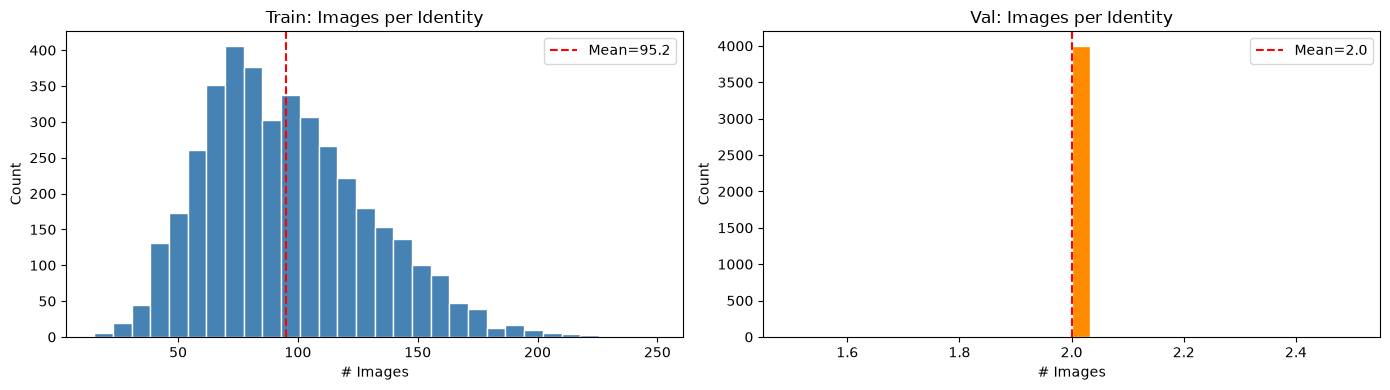

In [6]:
# Distribution of images per identity
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

axes[0].hist(train_counts, bins=30, color='steelblue', edgecolor='white')
axes[0].set_title('Train: Images per Identity')
axes[0].set_xlabel('# Images'); axes[0].set_ylabel('Count')
axes[0].axvline(np.mean(train_counts), color='red', linestyle='--',
                label=f'Mean={np.mean(train_counts):.1f}')
axes[0].legend()

axes[1].hist(val_counts, bins=30, color='darkorange', edgecolor='white')
axes[1].set_title('Val: Images per Identity')
axes[1].set_xlabel('# Images'); axes[1].set_ylabel('Count')
axes[1].axvline(np.mean(val_counts), color='red', linestyle='--',
                label=f'Mean={np.mean(val_counts):.1f}')
axes[1].legend()

plt.tight_layout()
plt.savefig(RESULT_DIR / 'dataset_distribution.png', dpi=120)
plt.show()

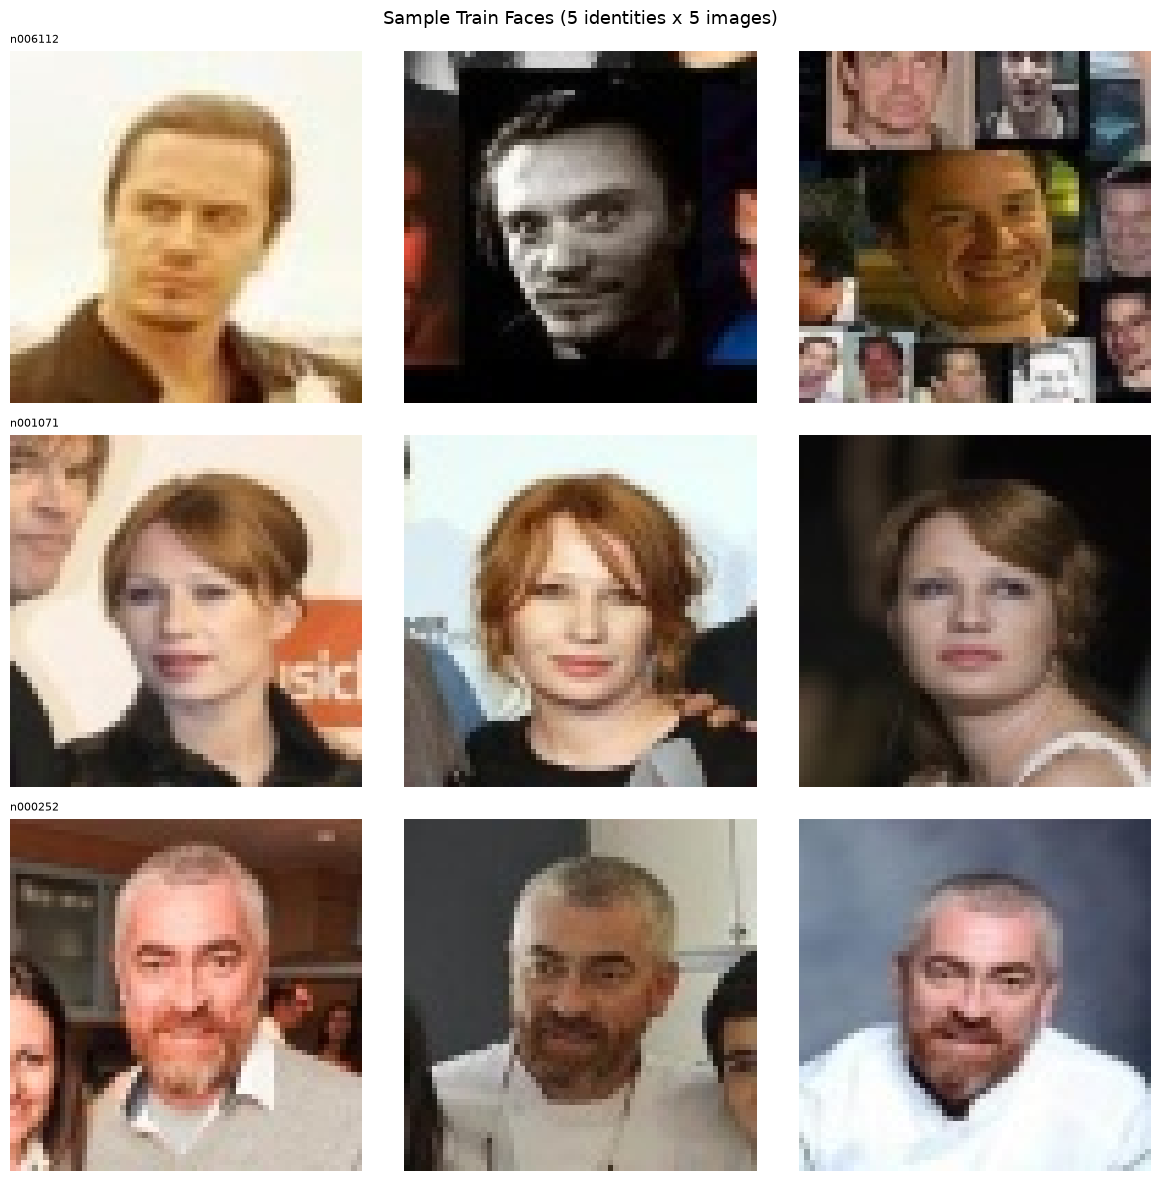

In [7]:
# Sample images grid (5 identities x 5 images)
sample_ids = random.sample(train_ids, 3)
fig, axes = plt.subplots(3, 3, figsize=(12, 12))

for row, identity in enumerate(sample_ids):
    imgs = sorted(identity.glob('*.jpg'))[:3]
    for col, img_path in enumerate(imgs):
        ax = axes[row][col]
        img = Image.open(img_path).convert('RGB')
        ax.imshow(img)
        ax.axis('off')
        if col == 0:
            ax.set_title(identity.name, fontsize=8, loc='left')

plt.suptitle('Sample Train Faces (5 identities x 5 images)', fontsize=13)
plt.tight_layout()
plt.savefig(RESULT_DIR / 'sample_faces.png', dpi=120)
plt.show()

## Section 2 – Datasets & DataLoaders

In [8]:
MEAN = [0.5, 0.5, 0.5]
STD  = [0.5, 0.5, 0.5]

train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomCrop(IMG_SIZE, padding=8),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.3, hue=0.1),
    transforms.RandomGrayscale(p=0.05),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

val_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.CenterCrop(IMG_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

In [9]:
# ---------- FaceClassificationDataset ----------
class FaceClassificationDataset(Dataset):
    """Standard folder dataset: returns (image_tensor, label_int)."""
    def __init__(self, root, transform=None):
        self.transform = transform
        self.samples   = []
        identity_dirs  = sorted([d for d in root.iterdir() if d.is_dir()])
        self.label_to_idx = {d.name: i for i, d in enumerate(identity_dirs)}
        self.num_classes  = len(identity_dirs)
        for id_dir in identity_dirs:
            label = self.label_to_idx[id_dir.name]
            for ext in ('*.jpg', '*.png'):
                for img_path in id_dir.glob(ext):
                    self.samples.append((img_path, label))
        print(f'  {root.name}: {len(self.samples):,} images, {self.num_classes:,} classes')

    def __len__(self):  return len(self.samples)

    def __getitem__(self, idx):
        img_path, label = self.samples[idx]
        img = Image.open(img_path).convert('RGB')
        if self.transform: img = self.transform(img)
        return img, label


# ---------- ClassBatchDataset (for semi-hard online mining) ----------
class ClassBatchDataset(Dataset):
    """Returns (image, label); use with ClassBatchSampler for P×K batches."""
    def __init__(self, root, transform=None):
        self.transform    = transform
        self.label_to_imgs = defaultdict(list)
        identity_dirs = sorted([d for d in root.iterdir() if d.is_dir()])
        for i, id_dir in enumerate(identity_dirs):
            imgs = list(id_dir.glob('*.jpg')) + list(id_dir.glob('*.png'))
            if len(imgs) >= 2:
                self.label_to_imgs[i] = imgs
        self.all_labels = list(self.label_to_imgs.keys())
        self.samples = [(img, lbl)
                        for lbl, imgs in self.label_to_imgs.items()
                        for img in imgs]
        print(f'  ClassBatch {root.name}: {len(self.samples):,} images, '
              f'{len(self.all_labels):,} usable identities')

    def __len__(self):  return len(self.samples)

    def __getitem__(self, idx):
        img_path, label = self.samples[idx]
        img = Image.open(img_path).convert('RGB')
        if self.transform: img = self.transform(img)
        return img, label


class ClassBatchSampler(torch.utils.data.Sampler):
    """Yields batches of P classes × K images (for online semi-hard mining).

    Args:
        label_to_imgs: dict {class_id: [list of img paths]}
        P: number of classes per batch
        K: number of samples per class
    """
    def __init__(self, label_to_imgs, P=16, K=4, drop_last=True):
        self.label_to_imgs = label_to_imgs
        self.labels = list(label_to_imgs.keys())
        self.P, self.K = P, K
        # flat index: list of (img_path, label) mirroring dataset.samples
        self.flat = [(img, lbl)
                     for lbl, imgs in label_to_imgs.items()
                     for img in imgs]
        self.img_to_idx = {img: i for i, (img, _) in enumerate(self.flat)}

    def __iter__(self):
        labels = self.labels.copy()
        random.shuffle(labels)
        batch = []
        for lbl in labels:
            imgs = self.label_to_imgs[lbl]
            chosen = random.choices(imgs, k=self.K)   # sample with replacement if needed
            batch.extend(self.img_to_idx[img] for img in chosen)
            if len(batch) >= self.P * self.K:
                yield batch[:self.P * self.K]
                batch = batch[self.P * self.K:]

    def __len__(self):
        return len(self.labels) // self.P


# ---------- VerificationDataset ----------
class VerificationDataset(Dataset):
    """Reads pairs_file, returns (img1, img2, label)."""
    def __init__(self, pairs_file, transform=None, has_labels=True):
        self.transform  = transform
        self.has_labels = has_labels
        self.pairs      = []
        base_dir = pairs_file.parent
        with open(pairs_file) as f:
            for line in f:
                parts = line.strip().split()
                if has_labels and len(parts) == 3:
                    self.pairs.append((base_dir/parts[0], base_dir/parts[1], int(parts[2])))
                elif not has_labels and len(parts) >= 2:
                    self.pairs.append((base_dir/parts[0], base_dir/parts[1], f'{parts[0]} {parts[1]}'))
        print(f'  {pairs_file.name}: {len(self.pairs):,} pairs')

    def __len__(self):  return len(self.pairs)

    def __getitem__(self, idx):
        p1, p2, meta = self.pairs[idx]
        def load(p):
            img = Image.open(p).convert('RGB')
            return self.transform(img) if self.transform else img
        return load(p1), load(p2), meta

In [10]:
print('=== Building Datasets ===')
clf_train_ds = FaceClassificationDataset(TRAIN_DIR, transform=train_transform)
clf_val_ds   = FaceClassificationDataset(VAL_DIR,   transform=val_transform)
NUM_CLASSES  = clf_train_ds.num_classes

triplet_train_ds = ClassBatchDataset(TRAIN_DIR, transform=train_transform)
_P, _K = 16, 4   # P classes × K images per batch (P*K must <= BATCH_SIZE)

verif_val_ds  = VerificationDataset(VAL_PAIRS,  transform=val_transform, has_labels=True)
verif_test_ds = VerificationDataset(TEST_PAIRS, transform=val_transform, has_labels=False)

# DataLoaders
clf_train_loader = DataLoader(clf_train_ds,   batch_size=BATCH_SIZE,    shuffle=True,
                              num_workers=NUM_WORKERS, pin_memory=True)
clf_val_loader   = DataLoader(clf_val_ds,     batch_size=BATCH_SIZE,    shuffle=False,
                              num_workers=NUM_WORKERS, pin_memory=True)
_sampler = ClassBatchSampler(triplet_train_ds.label_to_imgs, P=_P, K=_K)
triplet_loader   = DataLoader(triplet_train_ds, batch_sampler=_sampler,
                              num_workers=NUM_WORKERS, pin_memory=True)
verif_val_loader = DataLoader(verif_val_ds,   batch_size=128, shuffle=False,
                              num_workers=NUM_WORKERS, pin_memory=True)
verif_test_loader= DataLoader(verif_test_ds,  batch_size=128, shuffle=False,
                              num_workers=NUM_WORKERS, pin_memory=True)

print('\nAll DataLoaders ready.')

=== Building Datasets ===
  train_data: 380,638 images, 4,000 classes
  val_data: 8,000 images, 4,000 classes
  Triplet train_data: 380,638 images, 4,000 usable identities
  verification_pairs_val.txt: 8,805 pairs
  verification_pairs_test.txt: 51,835 pairs

All DataLoaders ready.


## Section 3 – CNN Architecture

In [11]:
# --- Building Blocks ---
class ConvBlock(nn.Module):
    """Conv3x3 -> BN -> ReLU -> optional MaxPool2d(2)"""
    def __init__(self, in_ch, out_ch, pool=False):
        super().__init__()
        layers = [
            nn.Conv2d(in_ch, out_ch, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
        ]
        if pool: layers.append(nn.MaxPool2d(2))
        self.block = nn.Sequential(*layers)

    def forward(self, x): return self.block(x)


class ResBlock(nn.Module):
    """Lightweight residual block (same spatial size in/out)."""
    def __init__(self, ch):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(ch, ch, 3, padding=1, bias=False), nn.BatchNorm2d(ch), nn.ReLU(inplace=True),
            nn.Conv2d(ch, ch, 3, padding=1, bias=False), nn.BatchNorm2d(ch),
        )

    def forward(self, x): return F.relu(self.net(x) + x, inplace=True)


# --- Backbone ---
class FaceCNN(nn.Module):
    """
    Custom CNN backbone.
    Input : (B, 3, 112, 112)
    Output: (B, embed_dim) – L2-normalized

    Spatial flow:  112 -> 56 -> 28 -> 14 -> 7 -> 3 -> 1
    Channels:        3    32    64   128   256   512
    """
    def __init__(self, embed_dim=512):
        super().__init__()
        self.features = nn.Sequential(
            ConvBlock(3,   32,  pool=True),   # 112->56
            ConvBlock(32,  64,  pool=True),   # 56->28
            ResBlock(64),
            ConvBlock(64,  128, pool=True),   # 28->14
            ResBlock(128),
            ConvBlock(128, 256, pool=True),   # 14->7
            ResBlock(256),
            ConvBlock(256, 512, pool=True),   # 7->3
            nn.AdaptiveAvgPool2d(1),          # 3->1
        )
        self.emb_head = nn.Sequential(
            nn.Flatten(),
            nn.Linear(512, embed_dim),
            nn.BatchNorm1d(embed_dim),
        )

    def forward(self, x):
        x = self.features(x)
        x = self.emb_head(x)
        return F.normalize(x, p=2, dim=1)   # L2-normalize


# --- Method 1: Classification model ---
class FaceCNN_Classifier(nn.Module):
    def __init__(self, num_classes, embed_dim=512):
        super().__init__()
        self.backbone   = FaceCNN(embed_dim)
        self.classifier = nn.Linear(embed_dim, num_classes)

    def forward(self, x):
        emb    = self.backbone(x)
        logits = self.classifier(emb)
        return logits, emb

    def get_embedding(self, x): return self.backbone(x)


# --- Method 2: Triplet model ---
class FaceCNN_Triplet(nn.Module):
    def __init__(self, embed_dim=512):
        super().__init__()
        self.backbone = FaceCNN(embed_dim)

    def forward(self, a, p, n):
        return self.backbone(a), self.backbone(p), self.backbone(n)

    def get_embedding(self, x): return self.backbone(x)


# Quick check
def count_params(model):
    total = sum(p.numel() for p in model.parameters())
    print(f'  Total params: {total:,}')

print('=== FaceCNN_Classifier ===')
_m = FaceCNN_Classifier(NUM_CLASSES, EMBED_DIM)
count_params(_m)
_x = torch.randn(2, 3, IMG_SIZE, IMG_SIZE)
_logits, _emb = _m(_x)
print(f'  logits: {_logits.shape} | embedding: {_emb.shape}')
del _m, _x, _logits, _emb

=== FaceCNN_Classifier ===
  Total params: 5,435,328
  logits: torch.Size([2, 4000]) | embedding: torch.Size([2, 512])


## Section 4 – Method 1: Classification-based (Softmax + CrossEntropy)

In [12]:
def train_clf(model, loader, criterion, optimizer, device):
    model.train()
    total_loss, correct, total = 0.0, 0, 0
    for imgs, labels in tqdm(loader, desc='  Train', leave=False):
        imgs, labels = imgs.to(device), labels.to(device)
        optimizer.zero_grad()
        logits, _ = model(imgs)
        loss = criterion(logits, labels)
        loss.backward(); optimizer.step()
        total_loss += loss.item() * imgs.size(0)
        correct    += (logits.argmax(1) == labels).sum().item()
        total      += imgs.size(0)
    return total_loss/total, correct/total


@torch.no_grad()
def eval_clf(model, loader, criterion, device):
    model.eval()
    total_loss, correct, total = 0.0, 0, 0
    for imgs, labels in tqdm(loader, desc='  Val  ', leave=False):
        imgs, labels = imgs.to(device), labels.to(device)
        logits, _ = model(imgs)
        loss = criterion(logits, labels)
        total_loss += loss.item() * imgs.size(0)
        correct    += (logits.argmax(1) == labels).sum().item()
        total      += imgs.size(0)
    return total_loss/total, correct/total

In [13]:
model1    = FaceCNN_Classifier(NUM_CLASSES, EMBED_DIM).to(DEVICE)

In [14]:
criterion1 = nn.CrossEntropyLoss()
optimizer1 = torch.optim.AdamW(model1.parameters(), lr=LR, weight_decay=5e-4)
scheduler1 = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer1, T_max=EPOCHS)

history1 = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}
best_val_acc1 = 0.0

print(f'Training Method 1 for {EPOCHS} epochs on {DEVICE}...')
for epoch in range(1, EPOCHS+1):
    tr_loss, tr_acc = train_clf(model1, clf_train_loader, criterion1, optimizer1, DEVICE)
    va_loss, va_acc = eval_clf(model1,  clf_val_loader,   criterion1, DEVICE)
    scheduler1.step()
    history1['train_loss'].append(tr_loss)
    history1['train_acc'].append(tr_acc)
    history1['val_loss'].append(va_loss)
    history1['val_acc'].append(va_acc)
    if va_acc > best_val_acc1:
        best_val_acc1 = va_acc
        torch.save(model1.state_dict(), CKPT_DIR/'method1_best.pth')
        marker = ' <- BEST'
    else:
        marker = ''
    print(f'Ep {epoch:02d}/{EPOCHS} | Loss {tr_loss:.4f}/{va_loss:.4f} | '
          f'Acc {tr_acc*100:.2f}%/{va_acc*100:.2f}%{marker}')

print(f'\nBest Val Acc (M1): {best_val_acc1*100:.2f}%')

Training Method 1 for 35 epochs on cuda...


Ep 01/35 | Loss 7.6725/7.2001 | Acc 0.42%/0.73% <- BEST


Ep 02/35 | Loss 6.6768/6.4227 | Acc 2.43%/2.65% <- BEST


Ep 03/35 | Loss 5.9622/5.7827 | Acc 6.05%/5.85% <- BEST


Ep 04/35 | Loss 5.3561/5.2451 | Acc 11.31%/10.72% <- BEST


Ep 05/35 | Loss 4.8338/4.7561 | Acc 17.27%/16.31% <- BEST


... (26 outputs left out)

Ep 32/35 | Loss 1.2698/1.6682 | Acc 77.58%/68.99% <- BEST


Ep 33/35 | Loss 1.2636/1.6683 | Acc 77.66%/68.76%


Ep 34/35 | Loss 1.2588/1.6661 | Acc 77.72%/68.75%


Ep 35/35 | Loss 1.2555/1.6670 | Acc 77.87%/68.81%

Best Val Acc (M1): 68.99%


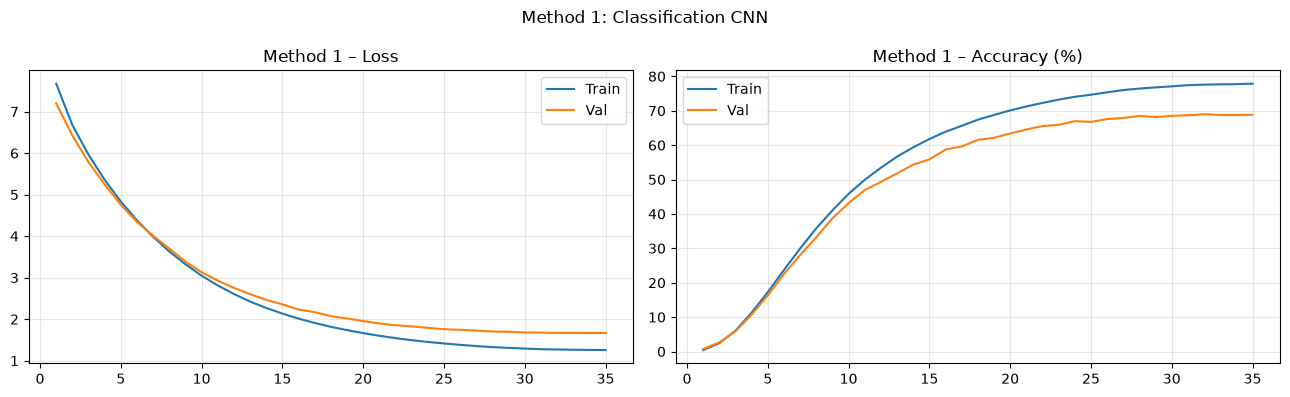

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
ep = range(1, EPOCHS+1)
axes[0].plot(ep, history1['train_loss'], label='Train')
axes[0].plot(ep, history1['val_loss'],   label='Val')
axes[0].set_title('Method 1 – Loss'); axes[0].legend(); axes[0].grid(alpha=0.3)
axes[1].plot(ep, [a*100 for a in history1['train_acc']], label='Train')
axes[1].plot(ep, [a*100 for a in history1['val_acc']],   label='Val')
axes[1].set_title('Method 1 – Accuracy (%)'); axes[1].legend(); axes[1].grid(alpha=0.3)
plt.suptitle('Method 1: Classification CNN', fontsize=12)
plt.tight_layout()
plt.savefig(RESULT_DIR/'method1_curves.png', dpi=120)
plt.show()

## Section 5 – Method 2: Metric Learning (Triplet Loss, Semi-Hard Mining)

In [19]:
def pairwise_dist(embeddings, eps=1e-12):
    """Numerically stable pairwise L2 distance for L2-normalised embeddings.

    For unit vectors: ||a-b||^2 = 2 - 2<a,b>  (always >= 0).
    eps inside sqrt avoids NaN gradients when distance -> 0.
    """
    dot   = torch.mm(embeddings, embeddings.t()).clamp(-1.0, 1.0)
    dist2 = (2.0 - 2.0 * dot).clamp(min=0.0)
    return (dist2 + eps).sqrt()          # (B, B), diagonal ~ sqrt(eps) ~ 0


def batch_semi_hard_triplet_loss(embeddings, labels, margin=0.3):
    """Online semi-hard triplet mining within a P×K class batch.

    For each anchor i:
      - positives : same label, i != j
      - negatives : different label
      - semi-hard : d(a,p) < d(a,n) < d(a,p) + margin
        Falls back to the hardest negative when no semi-hard neg exists.

    Args:
        embeddings : (B, D) L2-normalised tensor
        labels     : (B,)  integer class labels
        margin     : float
    Returns:
        scalar loss averaged over valid anchors
    """
    B     = embeddings.size(0)
    dist  = pairwise_dist(embeddings)           # (B, B)

    # Build masks  (B, B):  [i,j] = True when condition holds for anchor=i, ref=j
    lab   = labels.view(-1)
    eye   = torch.eye(B, dtype=torch.bool, device=embeddings.device)
    pos_mask = (lab.unsqueeze(1) == lab.unsqueeze(0)) & ~eye   # same class, excl. self
    neg_mask = (lab.unsqueeze(1) != lab.unsqueeze(0))           # different class

    losses = []
    for i in range(B):
        pos_d = dist[i][pos_mask[i]]
        if pos_d.numel() == 0:
            continue
        d_ap = pos_d.max()                       # hardest positive

        neg_d = dist[i][neg_mask[i]]
        if neg_d.numel() == 0:
            continue

        # Semi-hard condition (use no_grad for mask to avoid double-diff issues)
        with torch.no_grad():
            semi = (neg_d > d_ap) & (neg_d < d_ap + margin)

        d_an = neg_d[semi].min() if semi.any() else neg_d.min()  # fallback: hardest neg

        loss_i = F.relu(d_ap - d_an + margin)
        losses.append(loss_i)

    if not losses:
        return embeddings.sum() * 0.0           # zero with grad_fn
    return torch.stack(losses).mean()


def train_triplet(model, loader, optimizer, device, margin=0.3):
    """Training loop with online semi-hard triplet mining."""
    model.train()
    total_loss, n_batches = 0.0, 0
    for imgs, labels in tqdm(loader, desc='  Train', leave=False):
        imgs, labels = imgs.to(device), labels.to(device)
        optimizer.zero_grad()
        emb  = model.backbone(imgs)             # (B, D) L2-normalised
        loss = batch_semi_hard_triplet_loss(emb, labels, margin=margin)
        if torch.isnan(loss):                   # safety guard
            continue
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=5.0)
        optimizer.step()
        total_loss += loss.item()
        n_batches  += 1
    return total_loss / max(n_batches, 1)


@torch.no_grad()
def triplet_frac_correct(model, loader, device, n_batches=20):
    """Fraction of (anchor, pos, neg) relations where d(a,p) < d(a,n)."""
    model.eval()
    correct, total = 0, 0
    for i, (imgs, labels) in enumerate(loader):
        if i >= n_batches: break
        imgs, labels = imgs.to(device), labels.to(device)
        emb  = model.backbone(imgs)
        dist = pairwise_dist(emb)
        lab  = labels.view(-1)
        B    = emb.size(0)
        eye  = torch.eye(B, dtype=torch.bool, device=emb.device)
        pos_mask = (lab.unsqueeze(1) == lab.unsqueeze(0)) & ~eye
        neg_mask = (lab.unsqueeze(1) != lab.unsqueeze(0))
        for j in range(B):
            pd = dist[j][pos_mask[j]]
            nd = dist[j][neg_mask[j]]
            if pd.numel() == 0 or nd.numel() == 0: continue
            correct += int(pd.max().item() < nd.min().item())
            total   += 1
    return correct / total if total > 0 else 0.0

In [20]:
model2    = FaceCNN_Triplet(EMBED_DIM).to(DEVICE)
optimizer2 = torch.optim.AdamW(model2.parameters(), lr=LR, weight_decay=5e-4)
scheduler2 = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer2, T_max=EPOCHS)

history2 = {'train_loss': [], 'frac_correct': []}
best_loss2 = float('inf')

print(f'Training Method 2 for {EPOCHS} epochs on {DEVICE}...')
for epoch in range(1, EPOCHS+1):
    tr_loss  = train_triplet(model2, triplet_loader, optimizer2, DEVICE, margin=TRIPLET_MARGIN)
    frac_ok  = triplet_frac_correct(model2, triplet_loader, DEVICE)
    scheduler2.step()
    history2['train_loss'].append(tr_loss)
    history2['frac_correct'].append(frac_ok)
    if tr_loss < best_loss2:
        best_loss2 = tr_loss
        torch.save(model2.state_dict(), CKPT_DIR/'method2_best.pth')
        marker = ' <- BEST'
    else:
        marker = ''
    print(f'Ep {epoch:02d}/{EPOCHS} | Loss {tr_loss:.4f} | '
          f'd_pos<d_neg: {frac_ok*100:.1f}%{marker}')

print(f'\nBest Loss (M2): {best_loss2:.4f}')

Training Method 2 for 35 epochs on cuda...


Ep 01/35 | Loss 0.1528 | d_pos<d_neg: 85.6% <- BEST


Ep 02/35 | Loss 0.0818 | d_pos<d_neg: 92.2% <- BEST


Ep 03/35 | Loss 0.0601 | d_pos<d_neg: 91.6% <- BEST


Ep 04/35 | Loss 0.0463 | d_pos<d_neg: 90.9% <- BEST


Ep 05/35 | Loss 0.0395 | d_pos<d_neg: 94.1% <- BEST


... (26 outputs left out)

Ep 32/35 | Loss 0.0089 | d_pos<d_neg: 96.2% <- BEST


Ep 33/35 | Loss 0.0089 | d_pos<d_neg: 94.4%


Ep 34/35 | Loss 0.0086 | d_pos<d_neg: 95.3% <- BEST


Ep 35/35 | Loss 0.0086 | d_pos<d_neg: 95.0% <- BEST

Best Loss (M2): 0.0086


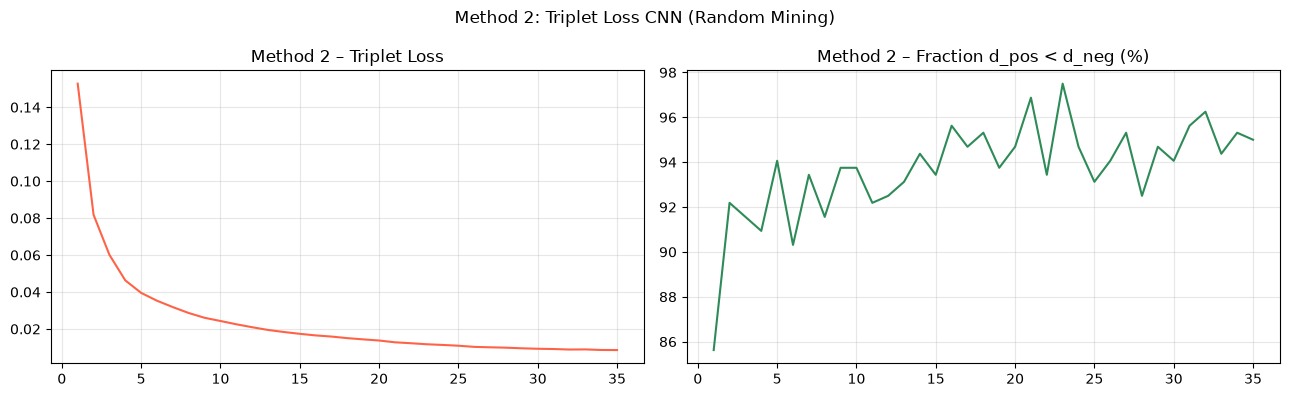

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
ep = range(1, EPOCHS+1)
axes[0].plot(ep, history2['train_loss'], color='tomato')
axes[0].set_title('Method 2 – Triplet Loss'); axes[0].grid(alpha=0.3)
axes[1].plot(ep, [f*100 for f in history2['frac_correct']], color='seagreen')
axes[1].set_title('Method 2 – Fraction d_pos < d_neg (%)'); axes[1].grid(alpha=0.3)
plt.suptitle('Method 2: Triplet Loss CNN (Semi-Hard Mining)', fontsize=12)
plt.tight_layout()
plt.savefig(RESULT_DIR/'method2_curves.png', dpi=120)
plt.show()

## Section 6 – Evaluation: ROC Curve & AUC

In [22]:
# Load best checkpoints
model1_eval = FaceCNN_Classifier(NUM_CLASSES, EMBED_DIM).to(DEVICE)
model1_eval.load_state_dict(torch.load(CKPT_DIR/'method1_best.pth', map_location=DEVICE))
model1_eval.eval()

model2_eval = FaceCNN_Triplet(EMBED_DIM).to(DEVICE)
model2_eval.load_state_dict(torch.load(CKPT_DIR/'method2_best.pth', map_location=DEVICE))
model2_eval.eval()

print('Best checkpoints loaded.')

Best checkpoints loaded.


In [23]:
@torch.no_grad()
def extract_pair_embeddings(model, loader, device):
    """Returns emb1 (N,D), emb2 (N,D), labels (N,)."""
    model.eval()
    e1s, e2s, lbls = [], [], []
    for img1, img2, label in tqdm(loader, desc='  Extracting'):
        e1s.append(model.get_embedding(img1.to(device)).cpu().numpy())
        e2s.append(model.get_embedding(img2.to(device)).cpu().numpy())
        lbls.append(np.array(label))
    return np.concatenate(e1s), np.concatenate(e2s), np.concatenate(lbls)


print('Extracting Method 1 embeddings...')
e1_m1, e2_m1, lbl_m1 = extract_pair_embeddings(model1_eval, verif_val_loader, DEVICE)
np.savez(EMBED_DIR/'method1_val.npz', emb1=e1_m1, emb2=e2_m1, labels=lbl_m1)

print('Extracting Method 2 embeddings...')
e1_m2, e2_m2, lbl_m2 = extract_pair_embeddings(model2_eval, verif_val_loader, DEVICE)
np.savez(EMBED_DIR/'method2_val.npz', emb1=e1_m2, emb2=e2_m2, labels=lbl_m2)

print('Done.')

Extracting Method 1 embeddings...


  Extracting:   0%|          | 0/69 [00:00<?, ?it/s]/tmp/ipykernel_894/2179675099.py:9: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  lbls.append(np.array(label))
  Extracting: 100%|██████████| 69/69 [00:02<00:00, 26.79it/s]


Extracting Method 2 embeddings...


  Extracting: 100%|██████████| 69/69 [00:02<00:00, 31.06it/s]

Done.


In [24]:
def cosine_sim(e1, e2):   return np.sum(e1 * e2, axis=1)             # L2-normed -> dot product
def euclidean_dist(e1, e2): return np.sqrt(np.sum((e1-e2)**2, axis=1))


def compute_roc_metrics(scores, labels):
    """scores: higher => same person."""
    fpr, tpr, thrs = roc_curve(labels, scores)
    roc_auc = auc(fpr, tpr)
    fnr = 1 - tpr
    eer = (fpr[np.nanargmin(np.abs(fnr - fpr))] + fnr[np.nanargmin(np.abs(fnr - fpr))]) / 2
    j   = tpr - fpr
    best_thr = thrs[np.argmax(j)]
    best_acc = accuracy_score(labels, (scores >= best_thr).astype(int))
    return fpr, tpr, roc_auc, eer, best_thr, best_acc


# Evaluate all 4 settings
settings = {
    'Method1 + Cosine':     (cosine_sim(e1_m1, e2_m1),      lbl_m1),
    'Method1 + Euclidean':  (-euclidean_dist(e1_m1, e2_m1), lbl_m1),
    'Method2 + Cosine':     (cosine_sim(e1_m2, e2_m2),      lbl_m2),
    'Method2 + Euclidean':  (-euclidean_dist(e1_m2, e2_m2), lbl_m2),
}

results = {}
for name, (scores, labels) in settings.items():
    fpr, tpr, rac, eer, thr, acc = compute_roc_metrics(scores, labels)
    results[name] = dict(fpr=fpr, tpr=tpr, auc=rac, eer=eer, thresh=thr, acc=acc)
    print(f'{name:30s}  AUC={rac:.4f}  EER={eer*100:.2f}%  BestAcc={acc*100:.2f}%')

Method1 + Cosine                AUC=0.9330  EER=12.94%  BestAcc=87.36%
Method1 + Euclidean             AUC=0.9330  EER=12.94%  BestAcc=87.36%
Method2 + Cosine                AUC=0.9064  EER=17.40%  BestAcc=83.03%
Method2 + Euclidean             AUC=0.9064  EER=17.40%  BestAcc=83.03%


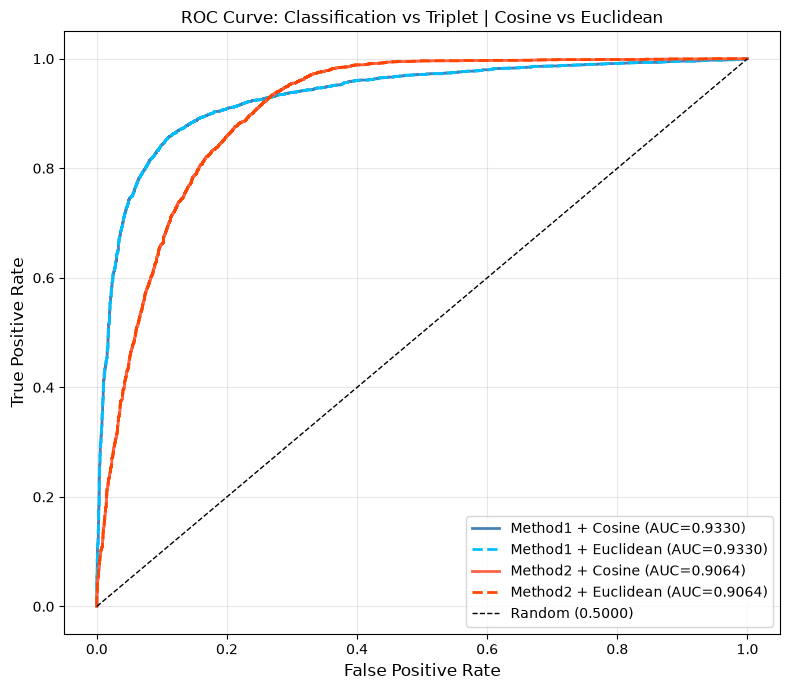

In [25]:
# ROC Curves
COLORS = ['steelblue', 'deepskyblue', 'tomato', 'orangered']
STYLES = ['-', '--', '-', '--']

plt.figure(figsize=(8, 7))
for (name, res), c, s in zip(results.items(), COLORS, STYLES):
    plt.plot(res['fpr'], res['tpr'], color=c, linestyle=s, lw=2,
             label=f"{name} (AUC={res['auc']:.4f})")
plt.plot([0,1],[0,1],'k--',lw=1, label='Random (0.5000)')
plt.xlabel('False Positive Rate', fontsize=12)
plt.ylabel('True Positive Rate', fontsize=12)
plt.title('ROC Curve: Classification vs Triplet | Cosine vs Euclidean', fontsize=12)
plt.legend(loc='lower right', fontsize=10)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(RESULT_DIR/'roc_curves.png', dpi=150)
plt.show()

In [26]:
# Summary table
print('='*72)
print(f'{"Method":<30} {"AUC":>8} {"EER":>8} {"Best Acc":>10} {"Threshold":>11}')
print('-'*72)
for name, res in sorted(results.items(), key=lambda x: -x[1]['auc']):
    print(f'{name:<30} {res["auc"]:>8.4f} {res["eer"]*100:>7.2f}% '
          f'{res["acc"]*100:>9.2f}% {res["thresh"]:>11.4f}')
print('='*72)

BEST_CONFIG = max(results, key=lambda k: results[k]['auc'])
print(f'\n>> Best configuration: {BEST_CONFIG}  (AUC={results[BEST_CONFIG]["auc"]:.4f})')

Method                              AUC      EER   Best Acc   Threshold
------------------------------------------------------------------------
Method1 + Cosine                 0.9330   12.94%     87.36%      0.2094
Method1 + Euclidean              0.9330   12.94%     87.36%     -1.2575
Method2 + Euclidean              0.9064   17.40%     83.03%     -0.9663
Method2 + Cosine                 0.9064   17.40%     83.03%      0.5331

>> Best configuration: Method1 + Cosine  (AUC=0.9330)


Computing t-SNE (this may take ~1 min)...


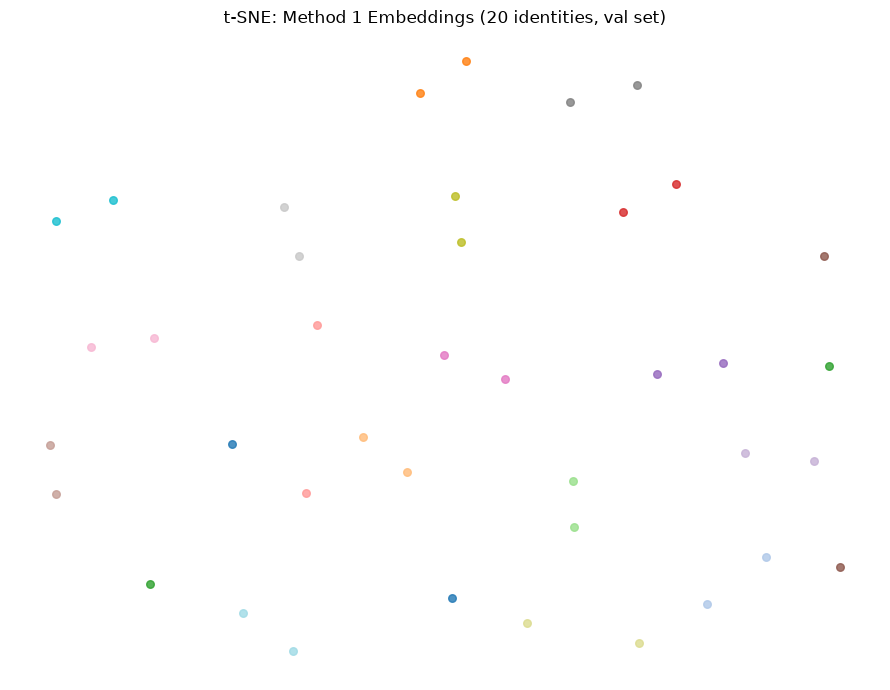

In [27]:
# t-SNE Visualization (20 identities, Method 1)
from sklearn.manifold import TSNE

@torch.no_grad()
def get_class_embeddings(model, root, n_ids=20, n_per_id=10, transform=None, device='cpu'):
    model.eval()
    id_dirs = random.sample([d for d in root.iterdir() if d.is_dir()], n_ids)
    embs, lbls = [], []
    for lbl, d in enumerate(id_dirs):
        for img_path in list(d.glob('*.jpg'))[:n_per_id]:
            img = Image.open(img_path).convert('RGB')
            if transform: img = transform(img)
            e = model.get_embedding(img.unsqueeze(0).to(device)).cpu().numpy().squeeze()
            embs.append(e); lbls.append(lbl)
    return np.array(embs), np.array(lbls)

print('Computing t-SNE (this may take ~1 min)...')
tsne_embs, tsne_lbls = get_class_embeddings(
    model1_eval, VAL_DIR, n_ids=20, n_per_id=10, transform=val_transform, device=DEVICE
)
xy = TSNE(n_components=2, perplexity=15, random_state=SEED).fit_transform(tsne_embs)

plt.figure(figsize=(9, 7))
colors = plt.cm.tab20(np.linspace(0, 1, 20))
for i in range(20):
    m = tsne_lbls == i
    plt.scatter(xy[m, 0], xy[m, 1], color=colors[i], s=30, alpha=0.8, label=f'ID {i}')
plt.title('t-SNE: Method 1 Embeddings (20 identities, val set)', fontsize=12)
plt.axis('off')
plt.tight_layout()
plt.savefig(RESULT_DIR/'tsne_method1.png', dpi=120)
plt.show()

## Section 7 – Test Submission

In [28]:
# Select best model & distance based on AUC
if 'Method1' in BEST_CONFIG:
    best_eval_model = model1_eval
else:
    best_eval_model = model2_eval

if 'Cosine' in BEST_CONFIG:
    score_fn  = cosine_sim
    threshold = results[BEST_CONFIG]['thresh']
else:
    score_fn  = lambda e1, e2: -euclidean_dist(e1, e2)
    threshold = results[BEST_CONFIG]['thresh']

print(f'Using: {BEST_CONFIG}')
print(f'Threshold: {threshold:.4f}')

# Extract test embeddings
@torch.no_grad()
def predict_test(model, loader, score_fn, threshold, device):
    model.eval()
    all_scores, all_meta = [], []
    for img1, img2, meta in tqdm(loader, desc='Test inference'):
        e1 = model.get_embedding(img1.to(device)).cpu().numpy()
        e2 = model.get_embedding(img2.to(device)).cpu().numpy()
        all_scores.extend(score_fn(e1, e2).tolist())
        all_meta.extend(meta)
    scores = np.array(all_scores)
    preds  = (scores >= threshold).astype(int)
    return all_meta, scores, preds

test_meta, test_scores, test_preds = predict_test(
    best_eval_model, verif_test_loader, score_fn, threshold, DEVICE
)
print(f'Test pairs: {len(test_preds):,} | Same: {test_preds.sum()} | Diff: {(~test_preds.astype(bool)).sum()}')

Using: Method1 + Cosine
Threshold: 0.2094


Test inference: 100%|██████████| 405/405 [00:10<00:00, 38.93it/s]

Test pairs: 51,835 | Same: 24971 | Diff: 26864


In [29]:
# Write submission.csv
sub_path = RESULT_DIR / 'submission.csv'
with open(sub_path, 'w', newline='') as f:
    writer = csv.writer(f)
    writer.writerow(['img1', 'img2', 'label'])
    for pair_str, pred in zip(test_meta, test_preds):
        img1_rel, img2_rel = pair_str.split(' ', 1)
        writer.writerow([img1_rel, img2_rel, int(pred)])

print(f'Submission saved: {sub_path}')

Submission saved: results/submission.csv


## Section 8 – Final Summary

In [30]:
print('='*70)
print('TASK 1 – FACE RECOGNITION: FINAL SUMMARY')
print('='*70)
print(f'Dataset      : {sum(train_counts):,} train | {sum(val_counts):,} val images')
print(f'Identities   : {NUM_CLASSES:,} (train)')
print(f'Embedding dim: {EMBED_DIM}  |  Image size: {IMG_SIZE}x{IMG_SIZE}  |  Epochs: {EPOCHS}')
print()
print('VERIFICATION AUC RESULTS (sorted by AUC):')
print('-'*70)
for name, res in sorted(results.items(), key=lambda x: -x[1]['auc']):
    mark = '  <- BEST' if name == BEST_CONFIG else ''
    print(f'  {name:<30}  AUC={res["auc"]:.4f}  EER={res["eer"]*100:.2f}%{mark}')
print('='*70)
print(f'Checkpoints : {CKPT_DIR}')
print(f'Embeddings  : {EMBED_DIR}')
print(f'Results     : {RESULT_DIR}')

TASK 1 – FACE RECOGNITION: FINAL SUMMARY
Dataset      : 380,638 train | 8,000 val images
Identities   : 4,000 (train)
Embedding dim: 512  |  Image size: 112x112  |  Epochs: 35

VERIFICATION AUC RESULTS (sorted by AUC):
----------------------------------------------------------------------
  Method1 + Cosine                AUC=0.9330  EER=12.94%  <- BEST
  Method1 + Euclidean             AUC=0.9330  EER=12.94%
  Method2 + Euclidean             AUC=0.9064  EER=17.40%
  Method2 + Cosine                AUC=0.9064  EER=17.40%
Checkpoints : checkpoints
Embeddings  : embeddings
Results     : results
